# Thai Toxic Text Detection

A reproducible notebook comparing a Thai word/character TF-IDF baseline with a fine-tuned WangchanBERTa encoder. Run cells from top to bottom. The notebook keeps the test split closed until model training and validation threshold selection are complete.

**Current result:** WangchanBERTa completed 3 training epochs on Apple MPS. Validation loss was lowest at epoch 2 (0.4443), then rose slightly at epoch 3 (0.4475), so the epoch-2 checkpoint was selected for test evaluation. On the fixed 324-post test set, TF-IDF reached macro-F1 0.732 and toxic recall 0.770; WangchanBERTa reached macro-F1 0.804 and toxic recall 0.880. Total encoder training time was about 374 seconds. Treat this as an initial comparison, not a production moderation system.

Dataset: tmu-nlp/thai_toxicity_tweet. The dataset card reports CC BY-NC 3.0. Text examples and review queues are sensitive; this notebook avoids displaying raw posts, and the local review CSVs should not be published.

## 0. Setup

Install dependencies from requirements.txt into the selected Python environment before running. The first data/model downloads require internet access. The paths below keep downloaded caches inside this project.

In [1]:
from pathlib import Path
import os, json, random, re, time, shutil, gc

ROOT = Path.cwd()
OUT = ROOT / "outputs"
RAW_DATA_CSV = ROOT / "data" / "thai_toxicity_raw.csv"
CACHE_ROOT = OUT / "cache"
OUT.mkdir(exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str((CACHE_ROOT / "matplotlib").resolve()))
os.environ.setdefault("PYTHAINLP_DATA", str((CACHE_ROOT / "pythainlp-data").resolve()))
os.environ.setdefault("HF_HOME", str((CACHE_ROOT / "huggingface").resolve()))
os.environ.setdefault("HF_DATASETS_CACHE", str((CACHE_ROOT / "huggingface/datasets").resolve()))
os.environ.setdefault("XDG_CACHE_HOME", str((CACHE_ROOT / "xdg").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import joblib
from datasets import load_dataset
from pythainlp.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
    Trainer, TrainingArguments)
from torch.utils.data import Dataset
from IPython.display import display, Image

SEED = 42
DATASET = "tmu-nlp/thai_toxicity_tweet"
DATASET_REVISION = "aa021e41d0ee6dbee2975fbed620ec8c586bdaf6"
ENCODER = "airesearch/wangchanberta-base-att-spm-uncased"
ENCODER_REVISION = "b81d38df6b4755dbedec0bfea863c9956cbb963e"
LABELS = ["non_toxic", "toxic"]
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
RUN_ENCODER = True
EPOCHS = 3
BATCH_SIZE = 16

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print({"device": DEVICE, "seed": SEED, "encoder_epochs": EPOCHS})

/Users/phuditpreechanarit/Desktop/TextDetection/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'device': 'mps', 'seed': 42, 'encoder_epochs': 3}


## 1. Load raw data, clean, and split

The project keeps the original 3,300-row Hugging Face export in `data/thai_toxicity_raw.csv` so the cleaning is visible and reproducible. This cell loads the raw CSV, then explicitly removes missing text, unavailable-text placeholders, blank posts, and normalized duplicate posts. It prints the row count after each step. The fixed train/validation/test indices are then loaded or created with seed 42.


In [2]:
def load_raw_data():
    if RAW_DATA_CSV.exists():
        raw = pd.read_csv(RAW_DATA_CSV, encoding="utf-8-sig", dtype={"tweet_id": "string"})
    else:
        raw = load_dataset(DATASET, split="train", trust_remote_code=True,
            revision=DATASET_REVISION).to_pandas()
    required = {"tweet_id", "tweet_text", "toxic_votes", "nontoxic_votes", "is_toxic"}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"Raw dataset is missing required columns: {sorted(missing)}")
    return raw.reset_index(drop=True)

def clean_data(raw):
    raw_rows = len(raw)
    present = raw[raw.tweet_text.notna()].copy()
    after_missing = len(present)

    present["text"] = present.tweet_text.astype(str).str.strip()
    available = present[present.text.ne("TWEET_NOT_FOUND")].copy()
    after_unavailable = len(available)
    nonblank = available[available.text.ne("")].copy()
    after_blank = len(nonblank)

    nonblank["label"] = pd.to_numeric(nonblank.is_toxic, errors="raise").astype(int)
    nonblank["toxic_votes"] = pd.to_numeric(nonblank.toxic_votes, errors="raise").astype(int)
    nonblank["nontoxic_votes"] = pd.to_numeric(nonblank.nontoxic_votes, errors="raise").astype(int)
    nonblank["dedup_key"] = nonblank.text.str.replace(r"\s+", " ", regex=True).str.strip().str.casefold()
    before_dedup = len(nonblank)
    cleaned = nonblank[nonblank.dedup_key.ne("")].drop_duplicates("dedup_key", keep="first")
    cleaned = cleaned.drop(columns=["dedup_key"]).reset_index(drop=True)

    steps = pd.DataFrame([
        {"cleaning step": "Raw rows loaded", "rows remaining": raw_rows, "rows removed": 0},
        {"cleaning step": "Remove missing tweet text", "rows remaining": after_missing, "rows removed": raw_rows - after_missing},
        {"cleaning step": "Remove unavailable-text placeholders", "rows remaining": after_unavailable, "rows removed": after_missing - after_unavailable},
        {"cleaning step": "Remove blank text", "rows remaining": after_blank, "rows removed": after_unavailable - after_blank},
        {"cleaning step": "Remove normalized duplicates", "rows remaining": len(cleaned), "rows removed": before_dedup - len(cleaned)},
    ])
    return cleaned, steps

def make_split(data):
    path = OUT / "split_indices.json"
    if path.exists():
        saved = json.loads(path.read_text())
        if saved["n_rows"] != len(data) or saved.get("dataset_revision") != DATASET_REVISION:
            raise RuntimeError("Saved split does not match this data revision/row count; review before making a new split.")
        parts = {name: np.asarray(ids, dtype=int) for name, ids in saved["indices"].items()}
    else:
        ids = np.arange(len(data))
        train_ids, rest_ids = train_test_split(ids, test_size=.30,
            random_state=SEED, stratify=data.label)
        val_ids, test_ids = train_test_split(rest_ids, test_size=.50,
            random_state=SEED, stratify=data.label.iloc[rest_ids])
        parts = {"train":train_ids,"validation":val_ids,"test":test_ids}
        payload = {"seed":SEED,"dataset_revision":DATASET_REVISION,
            "n_rows":len(data),"indices":{k:v.tolist() for k,v in parts.items()}}
        path.write_text(json.dumps(payload, indent=2))
    all_ids = np.concatenate(list(parts.values()))
    assert len(all_ids) == len(data) and len(np.unique(all_ids)) == len(data)
    return parts

def data_summary(data, parts):
    return {
        "dataset":DATASET,
        "usable_rows_after_missing_text_and_dedup":len(data),
        "class_counts":{LABELS[int(k)]:int(v) for k,v in data.label.value_counts().sort_index().items()},
        "toxic_share":float(data.label.mean()),
        "text_char_length_median":float(data.text.str.len().median()),
        "text_char_length_p95":float(data.text.str.len().quantile(.95)),
        "annotator_vote_split_2_to_1":int(((data.toxic_votes == 2) & (data.nontoxic_votes == 1) |
            (data.toxic_votes == 1) & (data.nontoxic_votes == 2)).sum()),
        "splits":{k:{"n":len(v),"toxic_share":float(data.label.iloc[v].mean())} for k,v in parts.items()},
        "seed":SEED,
    }

raw_posts = load_raw_data()
posts, cleaning_steps = clean_data(raw_posts)
parts = make_split(posts)
summary = data_summary(posts, parts)
(OUT / "data_summary.json").write_text(json.dumps(summary, indent=2))
display(cleaning_steps)
display(pd.DataFrame([{"split":k, **v} for k,v in summary["splits"].items()]))
print({k:v for k,v in summary.items() if k != "splits"})


,cleaning step,rows remaining,rows removed
0,Raw rows loaded,3300,0
1,Remove missing tweet text,2666,634
2,Remove unavailable-text placeholders,2160,506
3,Remove blank text,2160,0
4,Remove normalized duplicates,2160,0


,split,n,toxic_share
0,train,1512,0.616402
1,validation,324,0.617284
2,test,324,0.617284


{'dataset': 'tmu-nlp/thai_toxicity_tweet', 'usable_rows_after_missing_text_and_dedup': 2160, 'class_counts': {'non_toxic': 828, 'toxic': 1332}, 'toxic_share': 0.6166666666666667, 'text_char_length_median': 75.0, 'text_char_length_p95': 139.0, 'annotator_vote_split_2_to_1': 344, 'seed': 42}


## 2. Explore class balance and text length

This cell creates an aggregate plot without printing individual posts. The test rows are not used to fit either model.

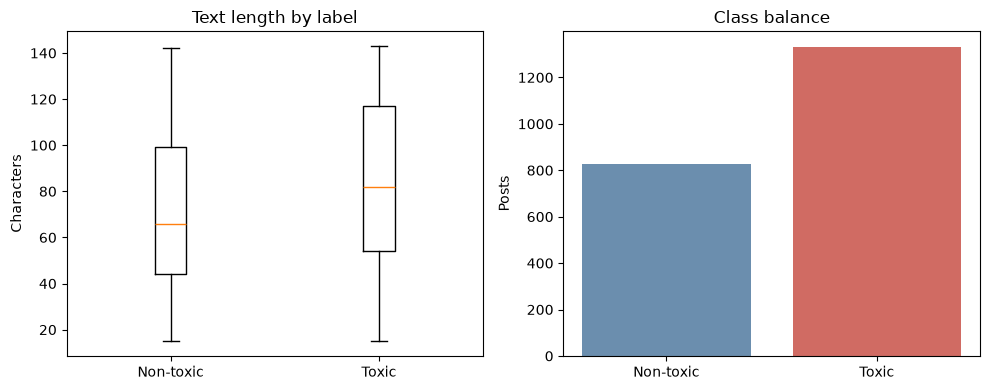

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
lengths = posts.text.str.len()
axes[0].boxplot([lengths[posts.label.eq(0)], lengths[posts.label.eq(1)]],
    tick_labels=["Non-toxic", "Toxic"], showfliers=False)
axes[0].set_title("Text length by label"); axes[0].set_ylabel("Characters")
counts = posts.label.value_counts().sort_index()
axes[1].bar(["Non-toxic", "Toxic"], [counts.get(0,0), counts.get(1,0)],
    color=["#6b8eae", "#d06b63"])
axes[1].set_title("Class balance"); axes[1].set_ylabel("Posts")
fig.tight_layout(); fig.savefig(OUT / "data_exploration.png", dpi=180); plt.show()

## 3. Define the models and evaluation helpers

The baseline uses Thai word tokens and character n-grams with balanced logistic regression. The encoder uses class-weighted cross-entropy. Threshold selection optimizes validation macro-F1; the selected value is frozen before test evaluation.

In [4]:
def thai_word_tokenize(text):
    return word_tokenize(text, engine="newmm", keep_whitespace=False)

def baseline_features(train_text, other_text):
    words = TfidfVectorizer(tokenizer=thai_word_tokenize, token_pattern=None,
        lowercase=False, ngram_range=(1,2), min_df=2, max_features=120_000,
        sublinear_tf=True)
    chars = TfidfVectorizer(analyzer="char", ngram_range=(2,5), min_df=2,
        max_features=180_000, sublinear_tf=True)
    union = FeatureUnion([("word", words), ("char", chars)])
    X_train = union.fit_transform(train_text)
    return union, X_train, union.transform(other_text)

def best_macro_f1_threshold(y, prob):
    _, _, candidates = precision_recall_curve(y, prob)
    candidates = np.r_[0.0, candidates, 1.0]
    scores = [f1_score(y, prob >= t, average="macro") for t in candidates]
    return float(candidates[int(np.nanargmax(scores))])

def metric_row(y, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {"macro_f1":float(f1_score(y, pred, average="macro")),
        "toxic_precision":float(precision_score(y, pred, zero_division=0)),
        "toxic_recall":float(recall_score(y, pred, zero_division=0)),
        "toxic_f1":float(f1_score(y, pred, zero_division=0)),
        "pr_auc":float(average_precision_score(y, prob)),
        "threshold":float(threshold),
        "confusion_matrix":confusion_matrix(y, pred, labels=[0,1]).tolist()}

class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=192):
        self.encoded = tokenizer(list(texts), truncation=True, padding="max_length", max_length=max_length)
        self.labels = list(map(int, labels))
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        row = {k:torch.tensor(v[i]) for k,v in self.encoded.items()}
        row["labels"] = torch.tensor(self.labels[i])
        return row

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs); self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weights = self.class_weights.to(outputs.logits.device)
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels, weight=weights)
        return (loss, outputs) if return_outputs else loss

def fit_encoder(train_df, val_df):
    tokenizer = AutoTokenizer.from_pretrained(ENCODER, revision=ENCODER_REVISION)
    model = AutoModelForSequenceClassification.from_pretrained(ENCODER,
        revision=ENCODER_REVISION, num_labels=2,
        id2label={0:LABELS[0], 1:LABELS[1]},
        label2id={label:i for i,label in enumerate(LABELS)})
    train_ds = TextDataset(train_df.text, train_df.label, tokenizer)
    val_ds = TextDataset(val_df.text, val_df.label, tokenizer)
    weights = compute_class_weight("balanced", classes=np.array([0,1]), y=train_df.label.to_numpy())
    args = TrainingArguments(output_dir=str(OUT / "encoder_checkpoints"),
        num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE*2, learning_rate=2e-5,
        weight_decay=.01, eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="eval_loss",
        save_total_limit=1, seed=SEED, data_seed=SEED, report_to="none",
        logging_steps=20, fp16=torch.cuda.is_available(),
        use_cpu=not (torch.cuda.is_available() or
            (hasattr(torch.backends, "mps") and torch.backends.mps.is_available())))
    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds,
        eval_dataset=val_ds, processing_class=tokenizer,
        class_weights=torch.tensor(weights, dtype=torch.float))
    started = time.perf_counter(); trainer.train(); seconds = time.perf_counter()-started
    model_path = OUT / "wangchanberta"
    trainer.save_model(str(model_path)); tokenizer.save_pretrained(str(model_path))
    return seconds

def encoder_probs(texts, tokenizer, model, batch=16):
    result = []
    for start in range(0, len(texts), batch):
        batch_text = list(texts[start:start+batch])
        enc = tokenizer(batch_text, return_tensors="pt", truncation=True,
            padding=True, max_length=192).to(DEVICE)
        with torch.no_grad():
            result.extend(torch.softmax(model(**enc).logits, dim=-1)[:,1].cpu().numpy().tolist())
    return np.asarray(result)

## 4. Fit the baseline on train data

Only the training rows fit the vectorizers and classifier. Validation rows select the threshold. The encoder is trained in the next cell before test evaluation.

In [5]:
train_df, val_df = (posts.iloc[parts[name]].reset_index(drop=True)
    for name in ("train", "validation"))
test_ids = parts["test"]

started = time.perf_counter()
vectorizer, X_train, X_val = baseline_features(train_df.text, val_df.text)
baseline_model = LogisticRegression(max_iter=1500, class_weight="balanced",
    solver="liblinear", random_state=SEED)
baseline_model.fit(X_train, train_df.label)
baseline_train_seconds = time.perf_counter() - started
joblib.dump({"vectorizer":vectorizer, "classifier":baseline_model}, OUT / "baseline.joblib")
training_times = {"baseline":{"train_seconds":baseline_train_seconds}}
print(f"Baseline training: {baseline_train_seconds:.3f} seconds")

Baseline training: 0.785 seconds


## 5. Fine-tune WangchanBERTa

This cell defaults to the one-epoch CPU run used in the report. Change EPOCHS or BATCH_SIZE above for a new experiment, and record that change with the resulting metrics. The saved split remains fixed.

In [6]:
if RUN_ENCODER:
    encoder_train_seconds = fit_encoder(train_df, val_df)
    training_times["wangchanberta"] = {"train_seconds":encoder_train_seconds}
else:
    encoder_train_seconds = None
training_times.update({"seed":SEED, "dataset_revision":DATASET_REVISION,
    "encoder_revision":ENCODER_REVISION if RUN_ENCODER else None,
    "epochs":EPOCHS if RUN_ENCODER else 0, "batch_size":BATCH_SIZE})
(OUT / "training_times.json").write_text(json.dumps(training_times, indent=2))
print(json.dumps(training_times, indent=2))

Some weights of CamembertForSequenceClassification were not initialized from the model checkpoint at airesearch/wangchanberta-base-att-spm-uncased and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/Users/phuditpreechanarit/Desktop/TextDetection/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.575700,0.508664
2,0.466200,0.444277
3,0.414300,0.447479


/Users/phuditpreechanarit/Desktop/TextDetection/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/phuditpreechanarit/Desktop/TextDetection/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{
  "baseline": {
    "train_seconds": 0.7849908749340102
  },
  "wangchanberta": {
    "train_seconds": 374.077219333034
  },
  "seed": 42,
  "dataset_revision": "aa021e41d0ee6dbee2975fbed620ec8c586bdaf6",
  "encoder_revision": "b81d38df6b4755dbedec0bfea863c9956cbb963e",
  "epochs": 3,
  "batch_size": 16
}


## 6. Select thresholds on validation and evaluate the held-out test set

The test labels are first accessed here, after fitting is complete. Validation macro-F1 chooses each threshold; the test set only reports final performance. Confusion-matrix order is true non-toxic/toxic by predicted non-toxic/toxic.

In [7]:
# Select every operating threshold using validation data only.
y_val = val_df.label.to_numpy()
started = time.perf_counter(); val_baseline_prob = baseline_model.predict_proba(X_val)[:,1]
val_baseline_ms = (time.perf_counter()-started)*1000/len(val_df)
baseline_threshold = best_macro_f1_threshold(y_val, val_baseline_prob)
thresholds = {"baseline":{"validation_objective":"macro-F1", "threshold":baseline_threshold}}
validation_times = {"baseline":val_baseline_ms}

if RUN_ENCODER:
    encoder_tokenizer = AutoTokenizer.from_pretrained(OUT / "wangchanberta")
    encoder_model = AutoModelForSequenceClassification.from_pretrained(OUT / "wangchanberta").to(DEVICE).eval()
    started = time.perf_counter(); val_encoder_prob = encoder_probs(val_df.text.tolist(), encoder_tokenizer, encoder_model)
    validation_times["wangchanberta"] = (time.perf_counter()-started)*1000/len(val_df)
    encoder_threshold = best_macro_f1_threshold(y_val, val_encoder_prob)
    thresholds["wangchanberta"] = {"validation_objective":"macro-F1", "threshold":encoder_threshold}

# Only after both validation thresholds are frozen do we select test rows.
test_df = posts.iloc[test_ids].reset_index(drop=True)
y_test = test_df.label.to_numpy()
started = time.perf_counter(); X_test = vectorizer.transform(test_df.text)
test_baseline_prob = baseline_model.predict_proba(X_test)[:,1]
baseline_infer_ms = (time.perf_counter()-started)*1000/len(test_df)
probabilities = {"baseline":test_baseline_prob}
results = {"baseline":metric_row(y_test, test_baseline_prob, baseline_threshold)}
results["baseline"].update(train_seconds=baseline_train_seconds,
    test_inference_ms_per_item=baseline_infer_ms)

if RUN_ENCODER:
    started = time.perf_counter(); test_encoder_prob = encoder_probs(test_df.text.tolist(), encoder_tokenizer, encoder_model)
    encoder_infer_ms = (time.perf_counter()-started)*1000/len(test_df)
    probabilities["wangchanberta"] = test_encoder_prob
    results["wangchanberta"] = metric_row(y_test, test_encoder_prob, encoder_threshold)
    results["wangchanberta"].update(train_seconds=encoder_train_seconds,
        test_inference_ms_per_item=encoder_infer_ms)

(OUT / "results.json").write_text(json.dumps(results, indent=2))
(OUT / "thresholds.json").write_text(json.dumps(thresholds, indent=2))
np.savez_compressed(OUT / "test_predictions.npz", y=y_test, **probabilities)
display(pd.DataFrame.from_dict(results, orient="index"))
print("Confusion matrices use [ [TN, FP], [FN, TP] ]")

,macro_f1,toxic_precision,toxic_recall,toxic_f1,pr_auc,threshold,confusion_matrix,train_seconds,test_inference_ms_per_item
baseline,0.732383,0.806283,0.77,0.787724,0.882945,0.527033,"[[87, 37], [46, 154]]",0.784991,0.233329
wangchanberta,0.803751,0.834123,0.88,0.856448,0.930825,0.454351,"[[89, 35], [24, 176]]",374.077219,3.629208


Confusion matrices use [ [TN, FP], [FN, TP] ]


## 7. Plot the precision–recall curves

Average precision is reported as PR-AUC in the results table. The plot and the metrics below are from the held-out test set.

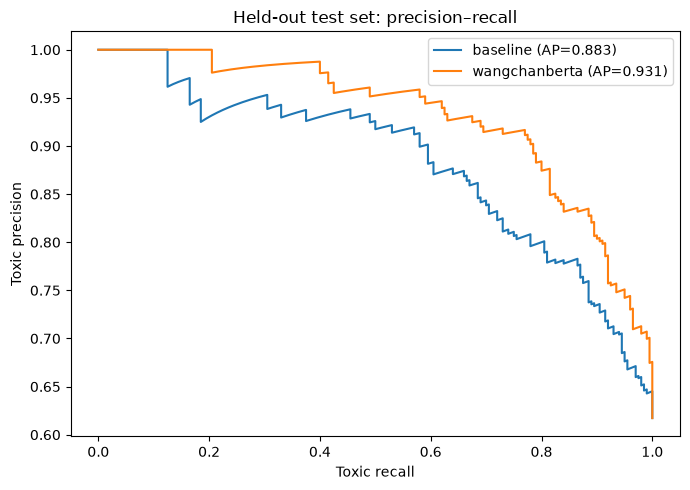

In [8]:
plt.figure(figsize=(7,5))
for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, prob):.3f})")
plt.xlabel("Toxic recall"); plt.ylabel("Toxic precision")
plt.title("Held-out test set: precision–recall"); plt.legend(); plt.tight_layout()
plt.savefig(OUT / "precision_recall.png", dpi=180); plt.show()

## 8. Create private error and label-audit queues

The CSVs contain raw posts. They are for local human review only. The category hints are simple automated heuristics, not human-confirmed causes. This cell does not estimate a label-noise rate; human adjudication is still required.

In [9]:
def error_group(text):
    value = text.lower()
    if re.search(r"[a-z]", value): return "mixed Thai-English"
    if re.search(r"(.)\1{2,}", value): return "repeated-character spelling"
    if re.search(r"555|ประชด|เหรอ|จ้า|🙄|😂", value): return "possible sarcasm / pragmatic cue"
    if re.search(r"\s", value): return "spacing / segmentation"
    return "slang, ambiguity, or missing context (manual review)"

audit_summary = {}
for name, prob in probabilities.items():
    threshold = thresholds[name]["threshold"]
    pred = (prob >= threshold).astype(int)
    positions = np.flatnonzero(pred != y_test)
    errors = test_df.iloc[positions].copy()
    errors["predicted_label"] = pred[positions]
    errors["confidence"] = np.maximum(prob[positions], 1-prob[positions])
    errors["error_group_hint"] = errors.text.map(error_group)
    errors["label_vote_margin"] = abs(errors.toxic_votes-errors.nontoxic_votes)
    errors.head(50)[["text","label","predicted_label","confidence","error_group_hint",
        "toxic_votes","nontoxic_votes","label_vote_margin"]].to_csv(
        OUT / f"{name}_errors_review.csv", index=False)
    ranked = positions[np.argsort(-np.maximum(prob[positions], 1-prob[positions]))[:50]]
    audit = test_df.iloc[ranked].copy()
    audit["predicted_label"] = pred[ranked]
    audit["confidence"] = np.maximum(prob[ranked], 1-prob[ranked])
    audit["meets_90pct_confidence"] = audit.confidence.ge(.90)
    audit["label_vote_margin"] = abs(audit.toxic_votes-audit.nontoxic_votes)
    audit["human_label_review"] = ""
    audit[["text","label","predicted_label","confidence","meets_90pct_confidence",
        "toxic_votes","nontoxic_votes","label_vote_margin","human_label_review"]].to_csv(
        OUT / f"{name}_label_audit.csv", index=False)
    audit_summary[name] = {"top_error_cases_queued":len(audit),
        "cases_at_least_90pct_confident":int(audit.meets_90pct_confidence.sum()),
        "cases_with_2_to_1_annotation_vote":int(audit.label_vote_margin.eq(1).sum()),
        "median_model_confidence":float(audit.confidence.median()) if len(audit) else None,
        "human_review_completed":False}
(OUT / "audit_summary.json").write_text(json.dumps(audit_summary, indent=2))
display(pd.DataFrame.from_dict(audit_summary, orient="index"))

,top_error_cases_queued,cases_at_least_90pct_confident,cases_with_2_to_1_annotation_vote,median_model_confidence,human_review_completed
baseline,50,0,10,0.606595,False
wangchanberta,50,1,13,0.688567,False


## 9. Robustness under simple text perturbations

These deterministic transformations are stress tests, not estimates of real-world frequency. Spacing inserts separators aggressively between Thai/Latin characters.

,original,repeat,spacing,emoji,spelling
baseline,0.77,0.780,0.535,0.78,0.770
wangchanberta,0.88,0.865,0.020,0.88,0.875


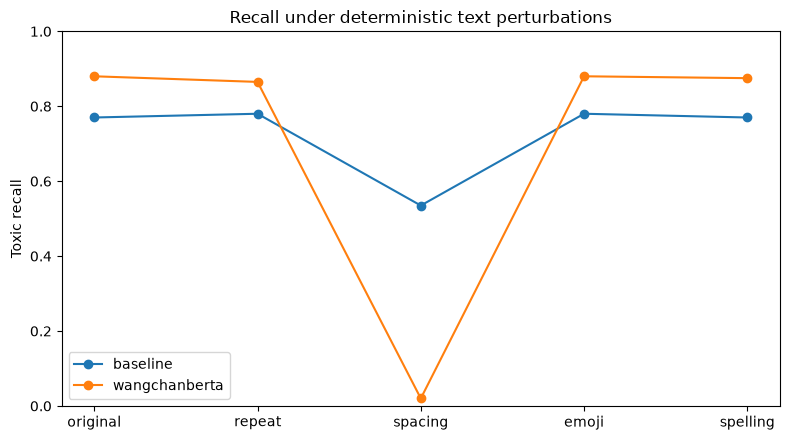

In [10]:
def perturb(text, kind):
    if not text: return text
    if kind == "repeat": return re.sub(r"(.)\1+", r"\1\1\1", text)
    if kind == "spacing": return re.sub(r"(?<=\S)(?=[ก-๙A-Za-z])", " ", text)
    if kind == "emoji": return text + " 😡"
    return re.sub(r"([ก-๙])\1", r"\1", text)

robustness = {}
for name, original_prob in probabilities.items():
    threshold = thresholds[name]["threshold"]
    scores = {"original":float(recall_score(y_test[y_test==1],
        (original_prob[y_test==1] >= threshold).astype(int), zero_division=0))}
    for kind in ("repeat", "spacing", "emoji", "spelling"):
        changed = [perturb(text, kind) for text in test_df.text.astype(str)]
        if name == "baseline":
            changed_prob = baseline_model.predict_proba(vectorizer.transform(changed))[:,1]
        else:
            changed_prob = encoder_probs(changed, encoder_tokenizer, encoder_model)
        scores[kind] = float(recall_score(y_test[y_test==1],
            (changed_prob[y_test==1] >= threshold).astype(int), zero_division=0))
    robustness[name] = scores
(OUT / "robustness.json").write_text(json.dumps(robustness, indent=2))
display(pd.DataFrame.from_dict(robustness, orient="index"))
fig, ax = plt.subplots(figsize=(8,4.5))
for name, values in robustness.items():
    ax.plot(list(values), list(values.values()), marker="o", label=name)
ax.set_ylabel("Toxic recall"); ax.set_ylim(0,1)
ax.set_title("Recall under deterministic text perturbations"); ax.legend(); fig.tight_layout()
fig.savefig(OUT / "robustness.png", dpi=180); plt.show()

## 10. Final report inside the notebook

This section summarizes the selected operating points and displays the figures inline. The outputs folder holds the model and machine-readable artifacts; there is no separate reports folder.


## Current saved-run report

WangchanBERTa training completed 3 epochs on Apple MPS. Validation loss was 0.508664 after epoch 1, 0.444277 after epoch 2, and 0.447479 after epoch 3. The epoch-2 checkpoint had the lowest validation loss and was restored for final test evaluation. The encoder training time below is for the full 3-epoch run. Confusion matrices use [ [TN, FP], [FN, TP] ].

| Model | Macro-F1 | Toxic precision | Toxic recall | Toxic F1 | PR-AUC | Threshold | Train sec | Test ms/item |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| TF-IDF + logistic regression | 0.732 | 0.806 | 0.770 | 0.788 | 0.883 | 0.527 | 0.8 | 0.233 |
| WangchanBERTa (3 training epochs; epoch-2 checkpoint selected) | 0.804 | 0.834 | 0.880 | 0.856 | 0.931 | 0.454 | 374.1 | 3.629 |

Confusion matrices: baseline `[[87, 37], [46, 154]]`; WangchanBERTa `[[89, 35], [24, 176]]`.

Toxic recall after perturbations (original, repeated characters, spacing, emoji, spelling):

| Model | Original | Repeat | Spacing | Emoji | Spelling |
|---|---:|---:|---:|---:|---:|
| TF-IDF + logistic regression | 0.770 | 0.780 | 0.535 | 0.780 | 0.770 |
| WangchanBERTa (epoch-2 checkpoint) | 0.880 | 0.865 | 0.020 | 0.880 | 0.875 |

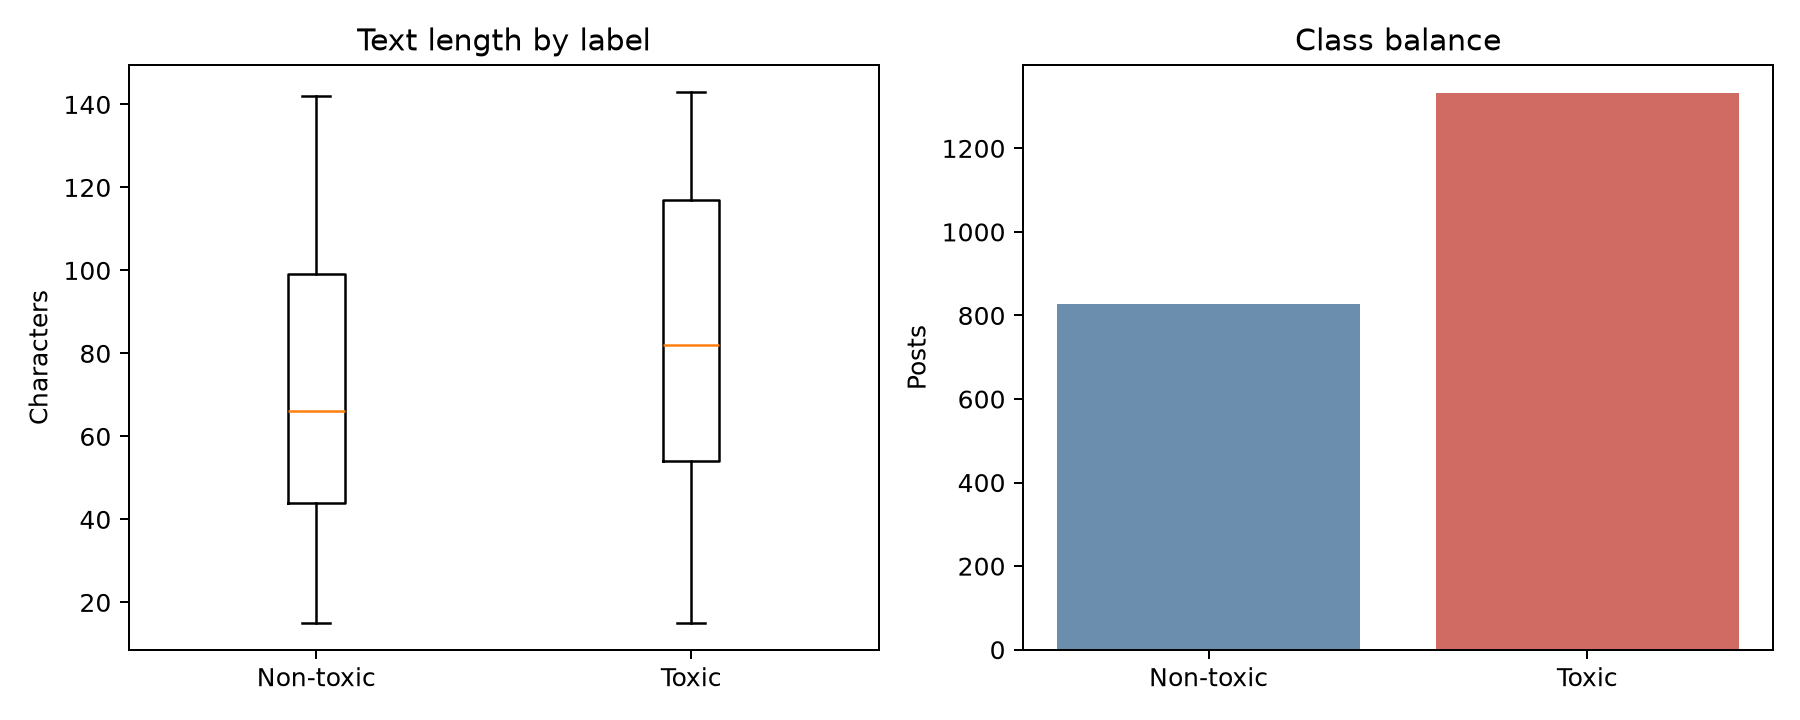
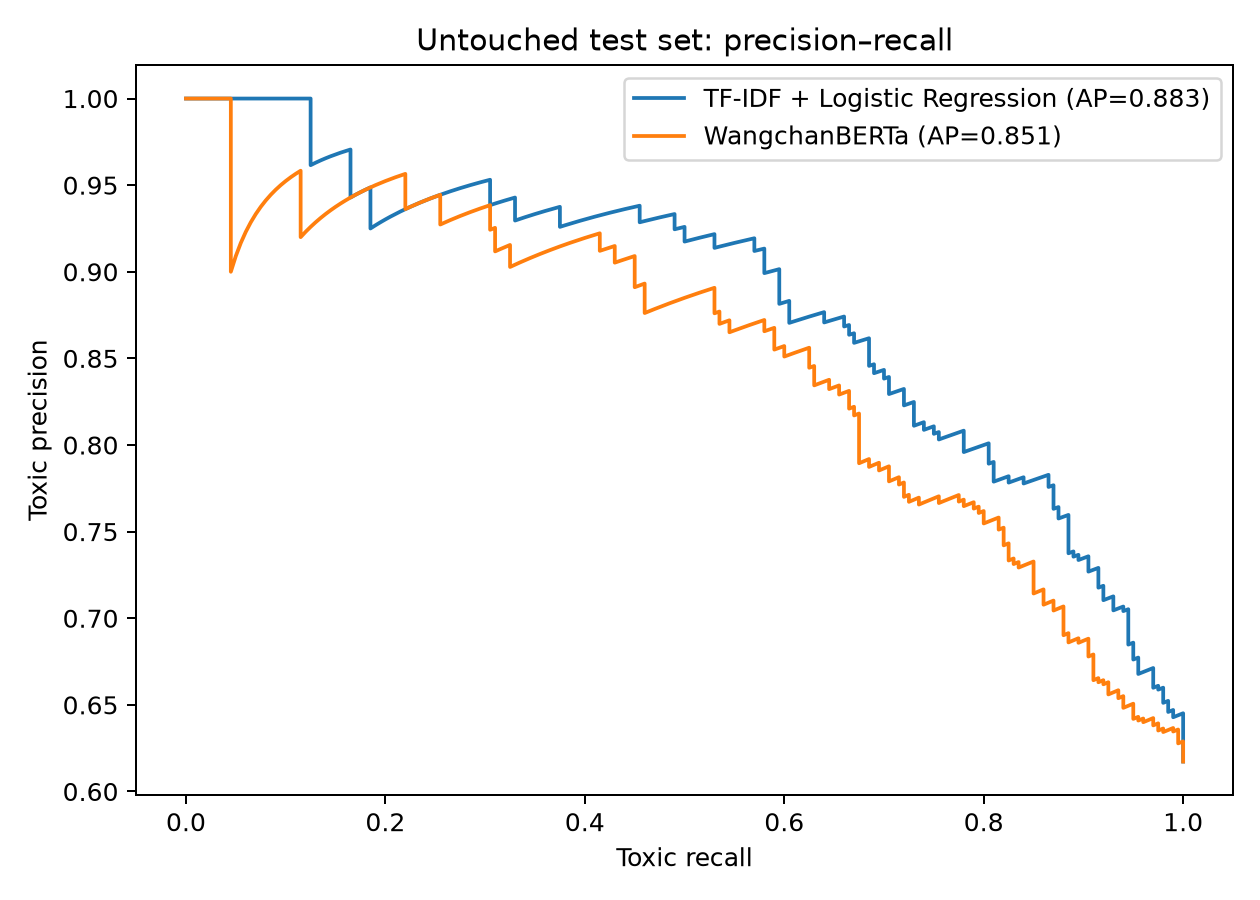
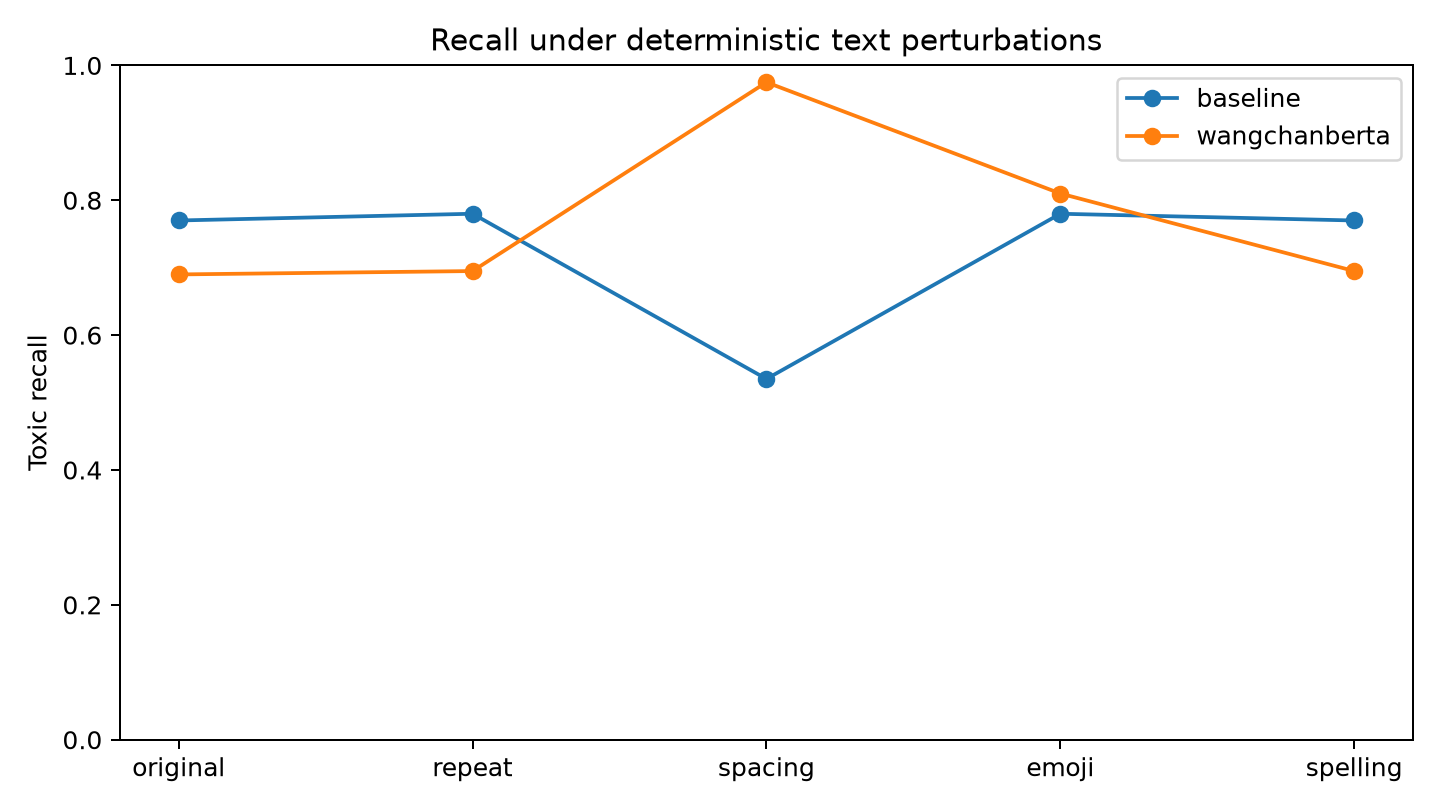


,macro_f1,toxic_precision,toxic_recall,toxic_f1,pr_auc,threshold,train_seconds,test_inference_ms_per_item
baseline,0.732383,0.806283,0.77,0.787724,0.882945,0.527033,0.784991,0.233329
wangchanberta,0.803751,0.834123,0.88,0.856448,0.930825,0.454351,374.077219,3.629208


baseline confusion matrix [ [TN, FP], [FN, TP] ]: [[87, 37], [46, 154]]
wangchanberta confusion matrix [ [TN, FP], [FN, TP] ]: [[89, 35], [24, 176]]
Audit queue summary:


,top_error_cases_queued,cases_at_least_90pct_confident,cases_with_2_to_1_annotation_vote,median_model_confidence,human_review_completed
baseline,50,0,10,0.606595,False
wangchanberta,50,1,13,0.688567,False


Toxic recall under perturbations:


,original,repeat,spacing,emoji,spelling
baseline,0.77,0.780,0.535,0.78,0.770
wangchanberta,0.88,0.865,0.020,0.88,0.875


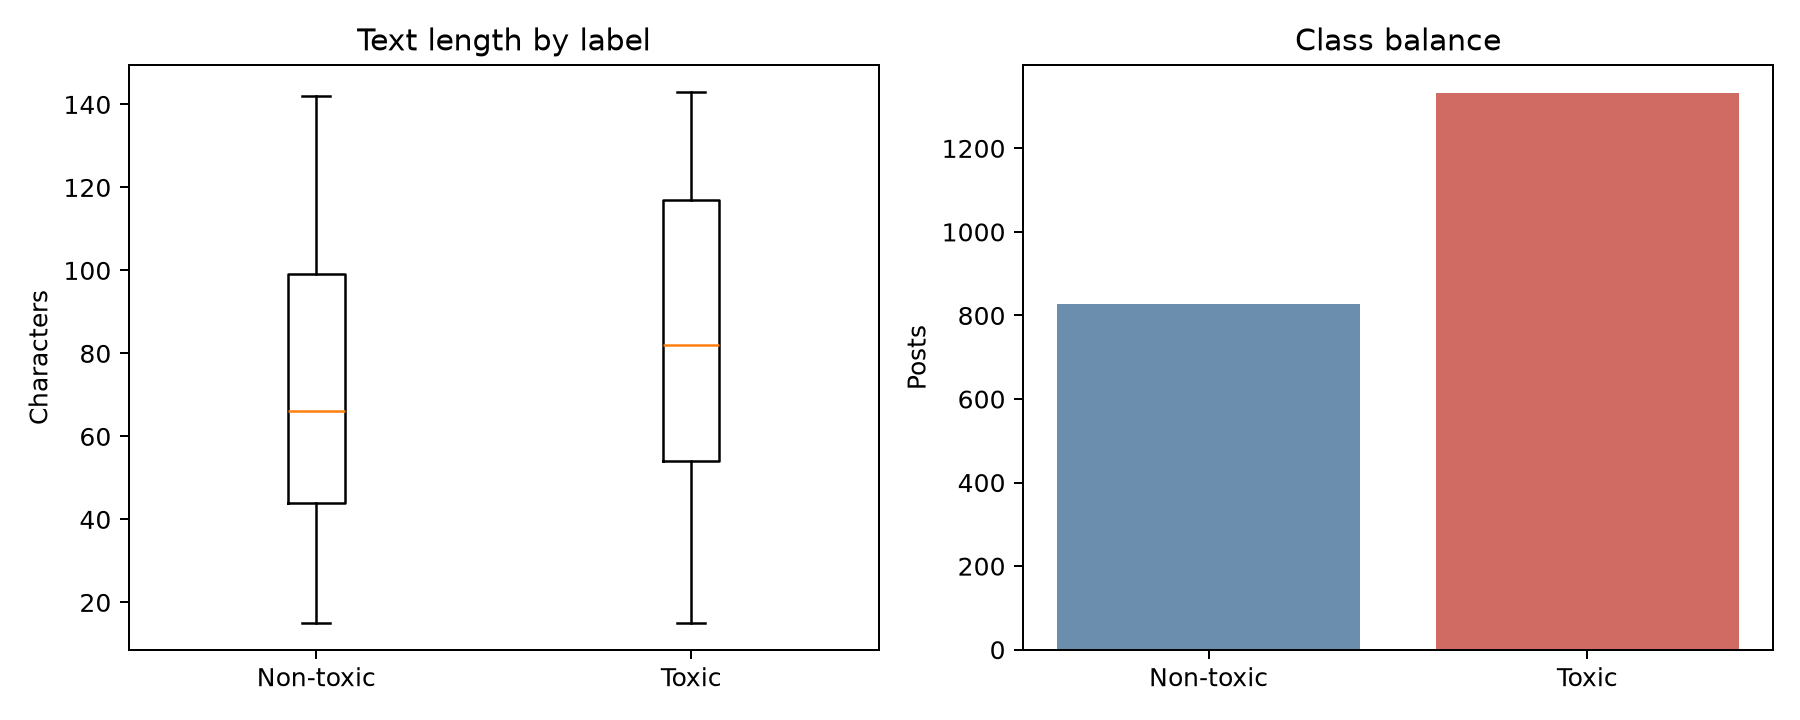

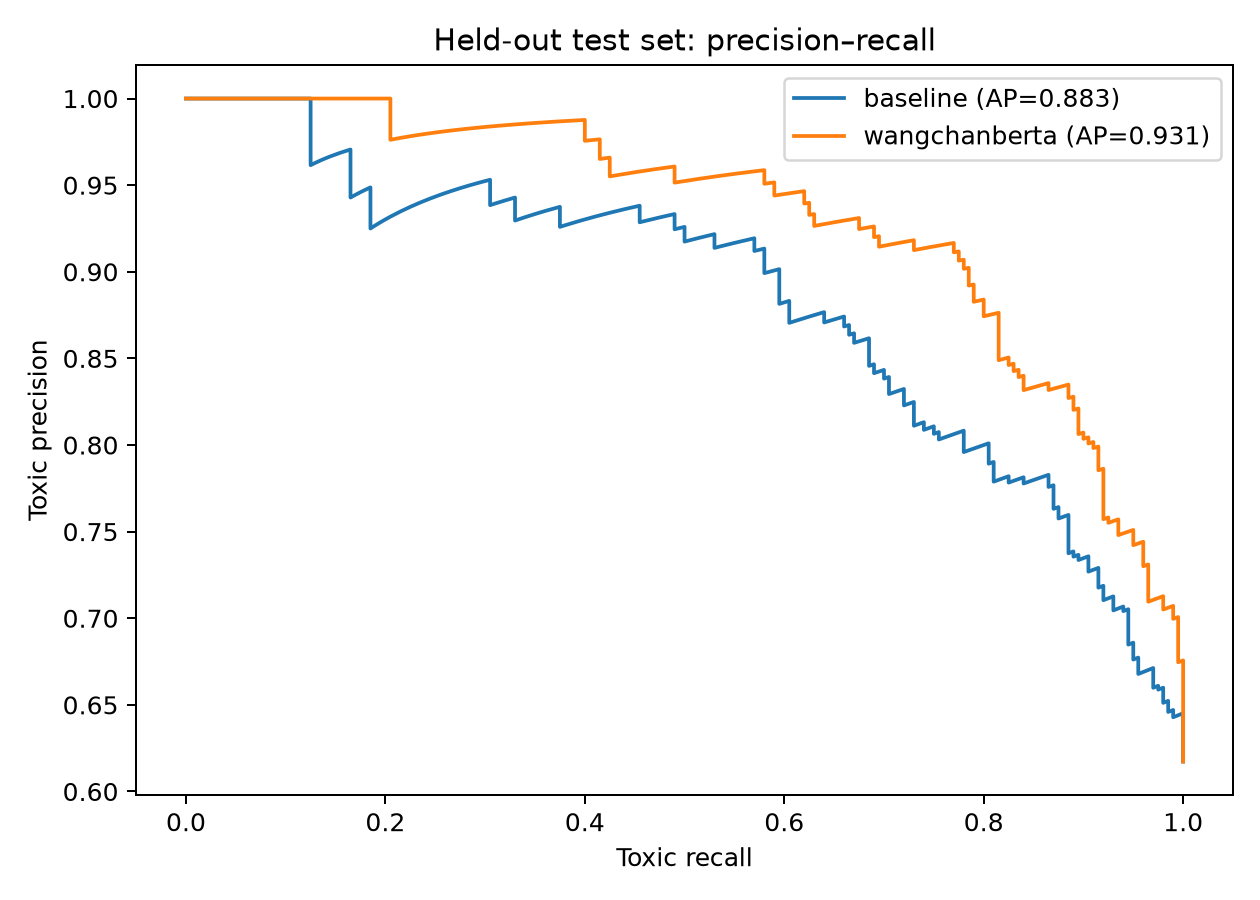

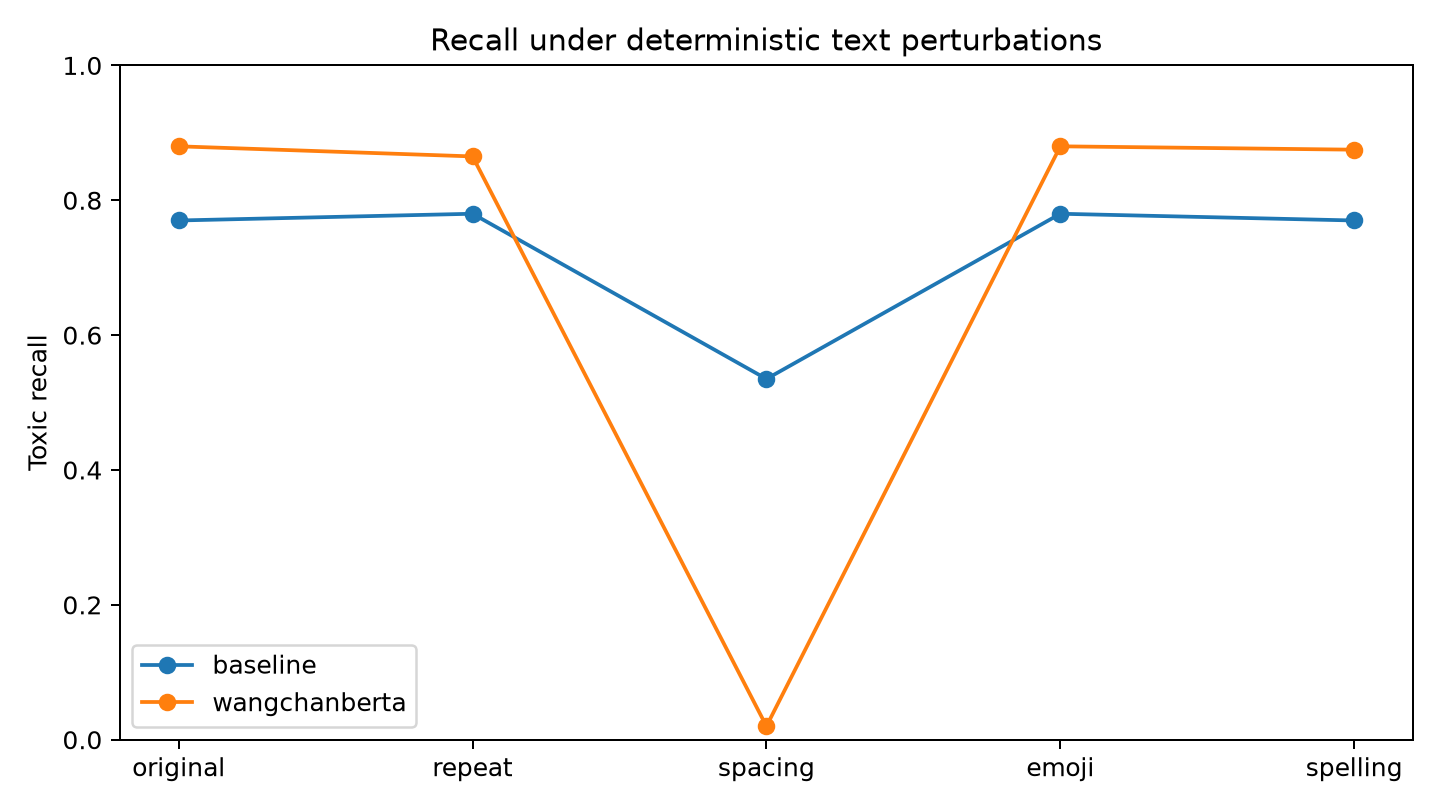

In [11]:
summary_columns = ["macro_f1", "toxic_precision", "toxic_recall", "toxic_f1", "pr_auc", "threshold", "train_seconds", "test_inference_ms_per_item"]
display(pd.DataFrame.from_dict(results, orient="index")[summary_columns])
for name, row in results.items():
    print(f"{name} confusion matrix [ [TN, FP], [FN, TP] ]: {row['confusion_matrix']}")
print("Audit queue summary:")
display(pd.DataFrame.from_dict(audit_summary, orient="index"))
print("Toxic recall under perturbations:")
display(pd.DataFrame.from_dict(robustness, orient="index"))
for filename in ("data_exploration.png", "precision_recall.png", "robustness.png"):
    display(Image(filename=str(OUT / filename)))
